# Random Forest: otimização, avaliação e interpretação (Fase 3)

**Objetivo:** construir o modelo de Random Forest para prever se um aluno **não** será
alfabetizado (classe de risco): validar, otimizar hiperparâmetros, avaliar no teste **uma
única vez** e interpretar.

O código reutilizável fica em `src/` (`preprocessing`, `modeling`, `evaluation`,
`visualization`); este notebook conta a história e mostra os resultados.

| Etapa | Aula de referência |
|---|---|
| Pipeline com pré-processamento integrado | Supervisionados, Aulas 5 (encoding) e 6 (scaling) |
| Overfitting × underfitting | Otimização, Aula 5 |
| `RandomizedSearchCV` | Otimização, Aula 2 (`slide33`) |
| Trade-off precisão × recall e limiar | Otimização, Aula 4 (`slide12`) |
| Avaliação final no teste, uma vez | Otimização, Aula 4 (`slide18`) |
| Feature importance e permutation importance | Otimização, Aula 1 (`slide56`, `slide58`) |
| SHAP | Otimização, Aula 3 (`slide38`, `slide50` a `slide52`) |

## 1. Setup

In [1]:
import sys
import time
import json
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # raiz do repositório no path (para importar src/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

from src.preprocessing.pipeline import preparar_dados, RANDOM_STATE
from src.modeling.modelos import ESPACOS_BUSCA, criar_pipeline, limitar_por_municipio
from src.modeling.treinar import treinar_sem_busca
from src.evaluation.avaliacao import (PASTA_RELATORIOS, curva_por_iteracao, calcular_shap, escolher_limiar,
                                      importancia_permutacao, probas_fora_da_amostra, salvar_resultados,
                                      treinar_e_avaliar)
from src.evaluation.comparar_teste import comparar_teste
from src.visualization.graficos import (plot_avaliacao_teste, plot_curva_iteracoes, plot_importancias,
                                        plot_precisao_recall_cv, plot_shap)

TETO_ALUNOS = 30        # alunos por município na busca de hiperparâmetros e na escolha do limiar
N_ITER_BUSCA = 12       # combinações do RandomizedSearchCV
TETO_PERMUTACAO = 20    # alunos por município do teste na permutation importance
TETO_SHAP = 3           # alunos por município do teste no SHAP
META_RECALL = 0.70                          # ponto de partida do limiar (decisão do grupo)

NOME = "random_forest"

## 2. Dados e divisão por município

`y = 1` é **não alfabetizado**. Treino e teste não compartilham municípios. O teste fica
reservado para a seção 7.

In [2]:
dados = preparar_dados()
print(f"Treino: {len(dados.y_treino):,} alunos, {dados.g_treino.nunique():,} municípios, risco {dados.y_treino.mean():.1%}")
print(f"Teste:  {len(dados.y_teste):,} alunos, {dados.g_teste.nunique():,} municípios, risco {dados.y_teste.mean():.1%}")

Treino: 1,320,423 alunos, 4,360 municípios, risco 40.9%
Teste:  290,331 alunos, 1,090 municípios, risco 39.3%


## 3. Amostra com teto de alunos por município (só para comparar e otimizar)

As features são municipais e se repetem em todos os alunos do município: os 1,3 milhão de
alunos do treino equivalem a cerca de **4.400 pontos independentes**. Para a busca usa-se
**no máximo `TETO_ALUNOS` alunos por município**: todos os municípios continuam
representados, a busca fica muito mais rápida e as capitais deixam de dominar o ajuste.
O teto vale só aqui; o modelo final treina no treino completo.

In [3]:
X_am, y_am, g_am = limitar_por_municipio(dados.X_treino, dados.y_treino, dados.g_treino, TETO_ALUNOS)
print(f"Amostra: {len(y_am):,} alunos, {g_am.nunique():,} municípios, risco {y_am.mean():.1%}")

Amostra: 125,981 alunos, 4,360 municípios, risco 37.3%


## 4. Overfitting: Random Forest sem limites × com limites

Aula 5 de Otimização: árvores sem limite de profundidade decoram o treino, e o sintoma é a
**diferença entre o score de treino e o de validação** (validação cruzada agrupada por município).

In [4]:
configs = {
    "Sem limites (max_depth=None, folha=1)": dict(n_estimators=100, max_depth=None, min_samples_leaf=1),
    "Com limites (max_depth=12, folha=50)":  dict(n_estimators=100, max_depth=12, min_samples_leaf=50),
}
linhas = {}
for rotulo, params in configs.items():
    t0 = time.time()
    cv = cross_validate(criar_pipeline(NOME, dados.decisoes, **params), X_am, y_am, groups=g_am,
                        cv=GroupKFold(n_splits=3), scoring={"roc_auc": "roc_auc", "recall": "recall"},
                        return_train_score=True)
    linhas[rotulo] = {"AUC treino": cv["train_roc_auc"].mean(), "AUC validação": cv["test_roc_auc"].mean(),
                      "recall treino": cv["train_recall"].mean(), "recall validação": cv["test_recall"].mean(),
                      "tempo (s)": time.time() - t0}
tabela_overfit = pd.DataFrame(linhas).T
tabela_overfit["gap AUC"] = tabela_overfit["AUC treino"] - tabela_overfit["AUC validação"]
display(tabela_overfit.round(3))

,AUC treino,AUC validação,recall treino,recall validação,tempo (s),gap AUC
"Sem limites (max_depth=None, folha=1)",0.749,0.684,0.481,0.348,10.722,0.065
"Com limites (max_depth=12, folha=50)",0.733,0.685,0.390,0.336,9.033,0.048


**Leitura:** a floresta sem limites tem **gap maior** entre treino e validação (e recall de
validação mais baixo) do que a regularizada, o que caracteriza overfitting. O AUC de treino
**não chega perto de 1,0**, e isso é um sinal dos dados: alunos do mesmo município têm
features idênticas e rótulos diferentes, então nenhuma árvore consegue separá-los. Só dá para
decorar o município. Limitar `max_depth` e `min_samples_leaf` é a regularização usada na busca.

## 5. Busca de hiperparâmetros

`RandomizedSearchCV` (Otimização, Aula 2, `slide33`) com **`GroupKFold`** no lugar do
`StratifiedKFold` dos slides: a validação cruzada precisa separar municípios, senão o score
fica inflado. O critério de seleção (`refit`) é o **ROC-AUC**, que não depende do limiar; o
recall é ajustado depois, na escolha do limiar (seção 6).

In [5]:
busca = RandomizedSearchCV(
    criar_pipeline(NOME, dados.decisoes), ESPACOS_BUSCA[NOME], n_iter=N_ITER_BUSCA,
    cv=GroupKFold(n_splits=3),
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall"},
    refit="roc_auc", n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
t0 = time.time()
busca.fit(X_am, y_am, groups=g_am)
print(f"Busca concluída em {(time.time() - t0) / 60:.1f} min")

colunas = ["param_modelo__n_estimators", "param_modelo__max_depth", "param_modelo__min_samples_leaf",
           "param_modelo__max_features", "mean_test_roc_auc", "mean_test_pr_auc", "mean_test_recall"]
resultados_busca = (pd.DataFrame(busca.cv_results_)[colunas]
                    .sort_values("mean_test_roc_auc", ascending=False).reset_index(drop=True))
resultados_busca.columns = [c.replace("param_modelo__", "").replace("mean_test_", "") for c in colunas]
display(resultados_busca.round(4))

melhores_params = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
print("Melhores hiperparâmetros:", melhores_params)
amplitude = resultados_busca["roc_auc"].max() - resultados_busca["roc_auc"].min()
print(f"ROC-AUC entre {resultados_busca['roc_auc'].min():.3f} e {resultados_busca['roc_auc'].max():.3f} "
      f"(amplitude {amplitude:.3f}; desvio entre folds ~0,01)")

PASTA_RELATORIOS.mkdir(parents=True, exist_ok=True)
resultados_busca.to_csv(PASTA_RELATORIOS / "random_forest_busca.csv", index=False, encoding="utf-8-sig")

Fitting 3 folds for each of 12 candidates, totalling 36 fits


Busca concluída em 2.0 min


,n_estimators,max_depth,min_samples_leaf,max_features,roc_auc,pr_auc,recall
0,100,12,100,sqrt,0.6854,0.5474,0.3355
1,100,16,100,sqrt,0.6854,0.5470,0.3376
2,200,8,20,0.3,0.6853,0.5478,0.3437
3,200,16,100,0.3,0.6851,0.5471,0.3560
4,100,12,100,0.3,0.6846,0.5472,0.3543
5,100,8,20,sqrt,0.6845,0.5470,0.3139
6,100,16,20,0.3,0.6843,0.5459,0.3586
7,100,16,50,0.3,0.6842,0.5461,0.3569
8,200,6,20,0.3,0.6839,0.5459,0.3194
9,100,6,100,0.3,0.6835,0.5454,0.3180


Melhores hiperparâmetros: {'n_estimators': 100, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 12}
ROC-AUC entre 0.683 e 0.685 (amplitude 0.003; desvio entre folds ~0,01)


**Leitura:** as 12 combinações ficaram entre ROC-AUC 0,683 e 0,685 (amplitude 0,003), diferença
menor que o desvio entre folds (~0,01). A escolha dos hiperparâmetros tem efeito desprezível, o
que indica que o desempenho é limitado pelos dados (features quase todas municipais) e não pela
configuração da floresta. A coluna `recall` da busca, entre 0,31 e 0,36, é medida no limiar
padrão de 0,5 e não reflete o desempenho final: o limiar é escolhido na seção seguinte.

## 6. Limiar de decisão (precisão × recall)

Otimização, Aula 4 (`slide12`). O limiar padrão de 0,5 não é sagrado. A métrica prioritária
é o **recall da classe de risco**, então o limiar é o **maior** que ainda atinge
`META_RECALL` (assim a precisão é a máxima possível). Usa previsões **fora da amostra** da
validação cruzada; o teste não é tocado.

`META_RECALL = 0,70` é um ponto de partida: o valor real deve vir da **capacidade de
atendimento da rede** (quantos alunos o programa de apoio consegue receber).

Limiar escolhido: 0.351 (recall 0.700, precisão 0.491)


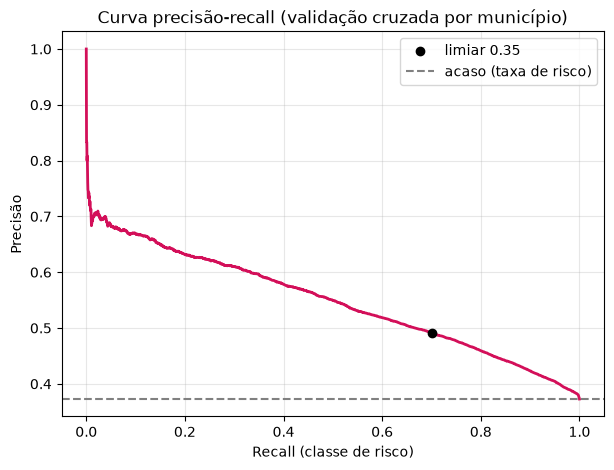

In [6]:
proba_oof = probas_fora_da_amostra(criar_pipeline(NOME, dados.decisoes, **melhores_params),
                                   X_am, y_am, g_am, n_splits=5)
escolha = escolher_limiar(y_am, proba_oof, META_RECALL)
LIMIAR = escolha["limiar"]
print(f"Limiar escolhido: {LIMIAR:.3f} (recall {escolha['recall']:.3f}, precisão {escolha['precisao']:.3f})")
plot_precisao_recall_cv(escolha, y_am.mean(), "rf_curva_precisao_recall_cv.png")

## 7. Avaliação final no teste (uma única vez)

Otimização, Aula 4 (`slide18`). O modelo final treina com **todo o treino** (sem teto) e os
hiperparâmetros da busca; o limiar vem da seção 6. A função `salvar_resultados` grava a
tabela, os parâmetros e as probabilidades do teste, que depois alimentam a comparação entre modelos.

> O treino usa 1,3 milhão de linhas e pode levar alguns minutos.

Treino final: 1,320,423 alunos em 0.5 min


,roc_auc,pr_auc,recall,precisao,f1,alertas (% dos alunos)
limiar 0.50,0.673,0.548,0.279,0.599,0.381,0.183
limiar 0.35 (escolhido),0.673,0.548,0.773,0.482,0.594,0.630


Taxa de risco no teste (precisão do acaso): 39.3%
Em risco: 114,219 | encontradas: 88,248 (77.3%) | não encontradas: 25,971
Alertas: 183,052 | corretos: 48.2% | alarmes falsos: 94,804


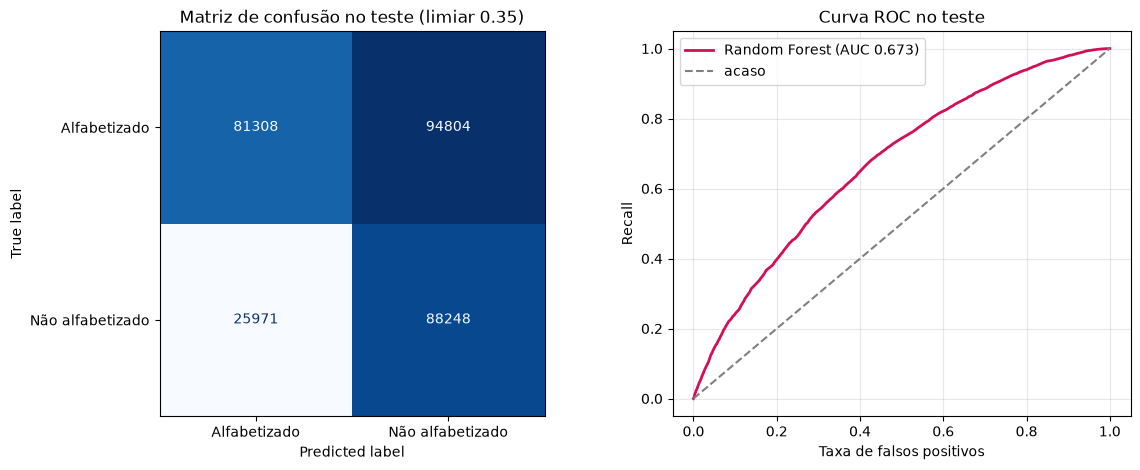

In [7]:
X_fit, y_fit = dados.X_treino, dados.y_treino
t0 = time.time()
modelo_final = criar_pipeline(NOME, dados.decisoes, **melhores_params).fit(X_fit, y_fit)
print(f"Treino final: {len(y_fit):,} alunos em {(time.time() - t0) / 60:.1f} min")

proba_teste, tabela_teste = salvar_resultados(NOME, modelo_final, dados, LIMIAR, META_RECALL,
                                              melhores_params, "Random Forest")
display(tabela_teste.round(3))

previsto = (proba_teste >= LIMIAR).astype(int)
y_t = dados.y_teste.values
vp = int(((previsto == 1) & (y_t == 1)).sum()); fn = int(((previsto == 0) & (y_t == 1)).sum())
fp = int(((previsto == 1) & (y_t == 0)).sum())
print(f"Taxa de risco no teste (precisão do acaso): {y_t.mean():.1%}")
print(f"Em risco: {vp + fn:,} | encontradas: {vp:,} ({vp / (vp + fn):.1%}) | não encontradas: {fn:,}")
print(f"Alertas: {vp + fp:,} | corretos: {vp / (vp + fp):.1%} | alarmes falsos: {fp:,}")
plot_avaliacao_teste(dados.y_teste, proba_teste, LIMIAR, "Random Forest", "rf_avaliacao_teste.png")

**Leitura:** ROC-AUC 0,673 e PR-AUC 0,548 no teste (acaso: 0,393). No limiar padrão de 0,5, o
modelo encontraria só 28% das crianças em risco. Com o limiar de 0,35, escolhido na validação
cruzada para recall-alvo de 0,70, o recall no teste foi 0,773 e a precisão 0,482, sinalizando
63% dos alunos.

O recall supera o alvo por uma diferença de contagem, não de método: o limiar é escolhido numa
amostra de até 30 alunos por município, em que cada cidade pesa quase igual, e o teste é contado
por aluno, em que os municípios grandes — com mais risco — pesam mais. Contado do mesmo jeito da
escolha, o recall no teste é de 0,694, no alvo (README, seção 7).

O ganho sobre o acaso é modesto (~1,2 vez na precisão): o modelo serve para **priorizar onde
olhar**, com muitos alarmes falsos. É instrumento de triagem, não de diagnóstico individual.

## 8. Comparação com o baseline no mesmo teste

O baseline do notebook 03 foi avaliado por validação cruzada no treino; aqui a regressão
logística é treinada e avaliada **no mesmo teste e com o mesmo critério de limiar** da floresta,
para a comparação ser justa. Compare principalmente **ROC-AUC e PR-AUC**, que não dependem do limiar.
Se os notebooks de outros modelos já tiverem rodado, eles entram na tabela automaticamente.

In [8]:
resultado_lr = treinar_sem_busca("regressao_logistica", dados, META_RECALL, TETO_ALUNOS)
tabela_comparacao = comparar_teste(dados)
display(tabela_comparacao.round(3))

,roc_auc,pr_auc,recall,precisao,f1,alertas (% dos alunos),limiar
HistGradientBoosting,0.674,0.552,0.665,0.509,0.577,0.514,0.474
Random Forest,0.673,0.548,0.773,0.482,0.594,0.630,0.351
Regressão logística,0.673,0.550,0.771,0.484,0.595,0.626,0.340
Árvore de decisão (rasa),0.664,0.528,0.605,0.517,0.557,0.461,0.486


## 9. Importância das features

Duas leituras (Otimização, Aula 1): a **importância por impureza** (`feature_importances_`),
rápida mas calculada no treino e enviesada para variáveis com muitos valores; e a
**permutation importance**, que embaralha cada feature no **teste** e mede a queda do ROC-AUC.

Como as features são municipais, a permutation usa uma amostra com **`TETO_PERMUTACAO` alunos
por município**: assim cada município pesa parecido e o ranking não é ditado pelas capitais.

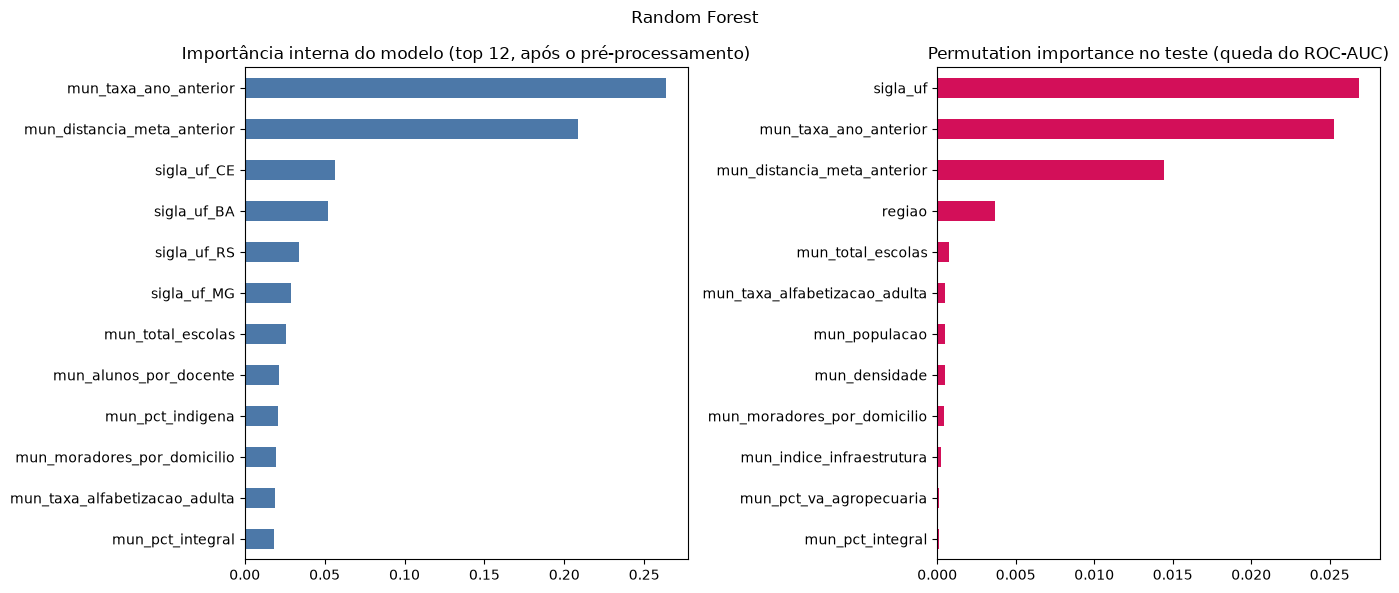

Permutation calculada em 21,575 alunos de 1,090 municípios


,queda do ROC-AUC
sigla_uf,0.0269
mun_taxa_ano_anterior,0.0253
mun_distancia_meta_anterior,0.0145
regiao,0.0037
mun_total_escolas,0.0007
mun_taxa_alfabetizacao_adulta,0.0005
mun_populacao,0.0005
mun_densidade,0.0005
mun_moradores_por_domicilio,0.0004
mun_indice_infraestrutura,0.0002


In [9]:
cols = list(dados.X_treino.columns)
X_perm, y_perm, g_perm = limitar_por_municipio(dados.X_teste, dados.y_teste, dados.g_teste, TETO_PERMUTACAO)
imp_perm = importancia_permutacao(modelo_final, X_perm[cols], y_perm, n_repeats=5)

pre, rf = modelo_final.named_steps["pre"], modelo_final.named_steps["modelo"]
nomes_saida = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
imp_impureza = pd.Series(rf.feature_importances_, index=nomes_saida).sort_values(ascending=False)

plot_importancias(imp_perm, imp_impureza, "Random Forest", "rf_importancia_features.png")
print(f"Permutation calculada em {len(y_perm):,} alunos de {g_perm.nunique():,} municípios")
display(imp_perm.head(10).round(4).to_frame("queda do ROC-AUC"))

## 10. SHAP

Otimização, Aula 3 (`slide38`, `slide50`, `slide52`). `TreeExplainer` aplicado a uma amostra do
teste com **`TETO_SHAP` alunos por município**, para que cada município (e cada UF) apareça
com seu peso real e não com os poucos pontos que o sorteio de alunos deixava para UFs pequenas.

`calcular_shap` trata os dois formatos de saída do `shap` (lista ou array 3D). Os valores
explicam **o modelo**, e como as features são municipais, explicam o município, não o aluno:
não use explicações individuais para rotular crianças.

shape dos valores SHAP (classe de risco): (3270, 52)


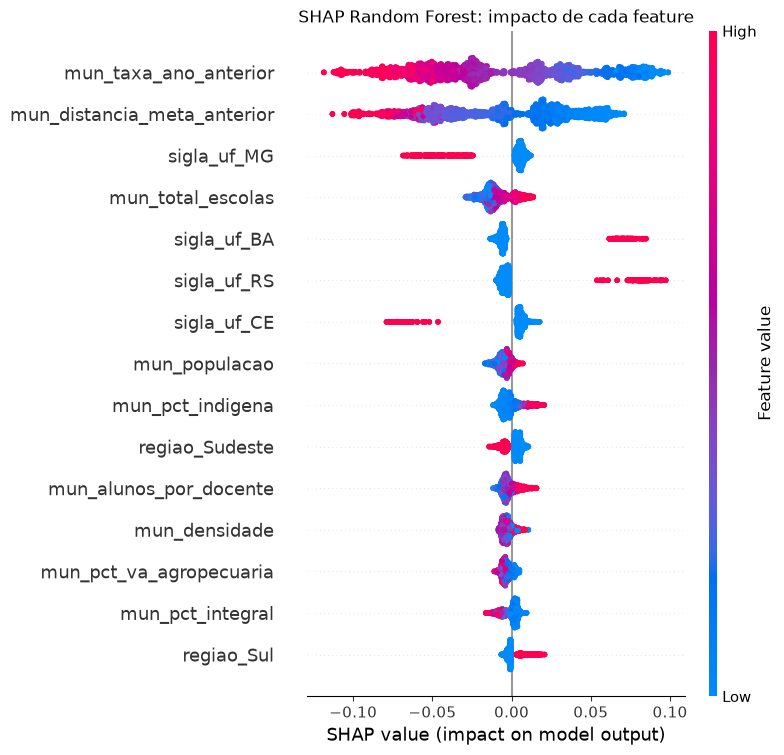

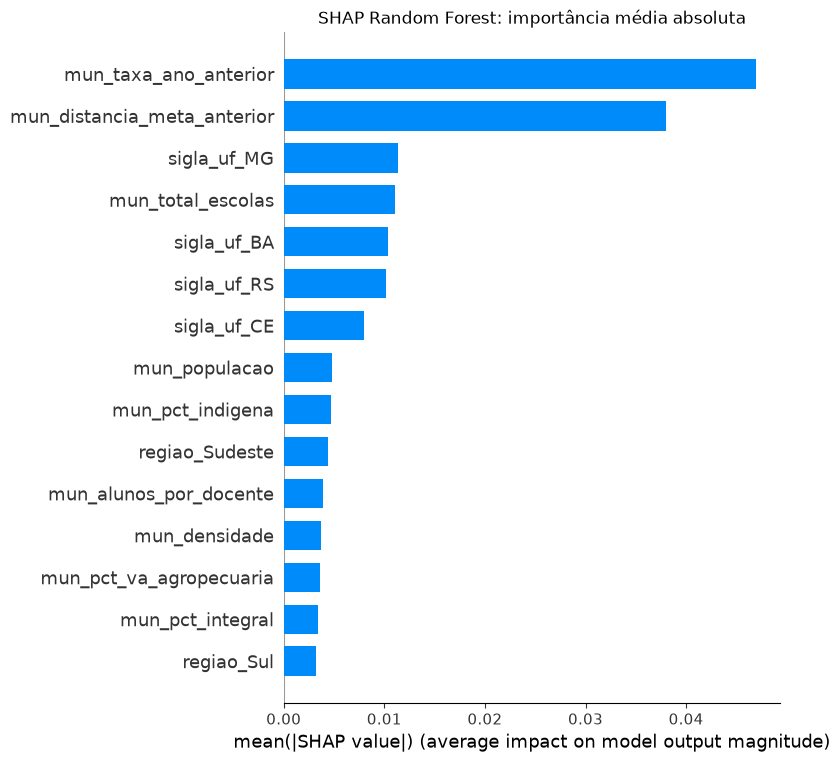

,|SHAP| médio
mun_taxa_ano_anterior,0.0470
mun_distancia_meta_anterior,0.0380
sigla_uf_MG,0.0114
mun_total_escolas,0.0111
sigla_uf_BA,0.0103
sigla_uf_RS,0.0102
sigla_uf_CE,0.0080
mun_populacao,0.0048
mun_pct_indigena,0.0047
regiao_Sudeste,0.0044


In [10]:
X_shap_bruto, _, _ = limitar_por_municipio(dados.X_teste, dados.y_teste, dados.g_teste, TETO_SHAP)
valores, X_shap, nomes_shap = calcular_shap(modelo_final, X_shap_bruto[cols])
print("shape dos valores SHAP (classe de risco):", valores.shape)
plot_shap(valores, X_shap, nomes_shap, "rf_shap", titulo="Random Forest")

shap_medio = pd.Series(np.abs(valores).mean(axis=0), index=nomes_shap).sort_values(ascending=False)
display(shap_medio.head(10).round(4).to_frame("|SHAP| médio"))

**Como ler o gráfico de pontos:** cada ponto é um aluno; no eixo horizontal, direita = a
feature empurrou a previsão para **mais risco**, esquerda = **menos risco**; a cor é o valor da
feature (vermelho = alto; nas variáveis de UF e região, vermelho = o aluno é dali).

**Leitura:** duas features concentram o impacto, `mun_taxa_ano_anterior` (0,047) e
`mun_distancia_meta_anterior` (0,038), e em ambas valores altos **reduzem** o risco: o município
que já alfabetizava bem, ou acima da meta, tende a continuar. Em seguida vêm as UFs — Minas
Gerais, Bahia, Rio Grande do Sul e Ceará — e o porte do município (`mun_total_escolas`,
`mun_populacao`). Cuidados:

- É **associação, não causa**.
- O efeito do **RS** é um choque de 2024 — mudança na medição ou efeito das enchentes —, não uma
  característica educacional estável do estado (seção 11).
- `mun_pct_rural` e `mun_pct_transporte` têm valores acima de 100% em 20 a 23% dos municípios,
  por numerador e denominador de etapas diferentes; o pipeline os limita no percentil 99 do
  treino, e a correção na origem está pendente.
- Variáveis correlacionadas (escolas, população, densidade) dividem a importância.

## 11. Sensibilidade A: o RS distorce o modelo?

A Fase 2 documentou que 89,6% dos municípios gaúchos "caíram" em 2024. Duas explicações são
compatíveis com os dados: uma **mudança na origem da medição**, apontada na Fase 2, ou o
**efeito das enchentes de 2024**, que suspenderam aulas por semanas (notebook 02). `uf_anomala`
foi descartada, mas `sigla_uf = RS` continua no modelo via one-hot, então o modelo pode estar
aprendendo esse choque. Aqui, dois modelos (mesmos hiperparâmetros, amostra com teto) são
avaliados no **mesmo teste sem as linhas do RS**: um treinado com o RS e outro sem.

In [11]:
_, com_rs, *_ = treinar_e_avaliar(NOME, melhores_params, dados, treino_sem_rs=False, teste_sem_rs=True, teto=TETO_ALUNOS)
_, sem_rs_, *_ = treinar_e_avaliar(NOME, melhores_params, dados, treino_sem_rs=True, teste_sem_rs=True, teto=TETO_ALUNOS)
sens_rs = pd.DataFrame({"treino com RS": com_rs, "treino sem RS": sem_rs_}).T
display(sens_rs.round(4))
sens_rs.to_csv(PASTA_RELATORIOS / "random_forest_sensibilidade_rs.csv", encoding="utf-8-sig")

,roc_auc,pr_auc
treino com RS,0.6726,0.5464
treino sem RS,0.6725,0.5456


**Como ler:** se os dois AUC são praticamente iguais, o choque do RS não distorce o desempenho
nos demais estados, mas o coeficiente de "RS" continua sem significado educacional estável e
deve ser sinalizado no README. Uma diferença clara indicaria que o RS está contaminando o ajuste
e pediria tratamento (excluir o RS do treino ou corrigir a origem do dado).

**Resultado:** ROC-AUC de 0,6726 com o RS no treino e 0,6725 sem — praticamente iguais. O RS
não distorce o desempenho nos demais estados e fica na base, como decidido no notebook 02:
excluí-lo removeria justamente os alunos de maior risco, se o efeito for real. O coeficiente do
estado está sinalizado no README, seções 8 e 10.

## 12. Sensibilidade B: o que explica o risco sem a "inércia"?

O modelo é dominado por `mun_taxa_ano_anterior` e `mun_distancia_meta_anterior`: o melhor
preditor de risco é o município já ter ido mal. Isso ajuda a priorizar, mas não responde à
pergunta do enunciado **"quais fatores mais impactam a alfabetização?"**. Aqui o modelo é
retreinado **sem essas duas features** para ver o que sobra (infraestrutura, porte, região,
perfil econômico) e quanto o AUC cai.

,roc_auc,pr_auc
com todas as features,0.6724,0.5499
sem as features de inércia,0.6468,0.5279


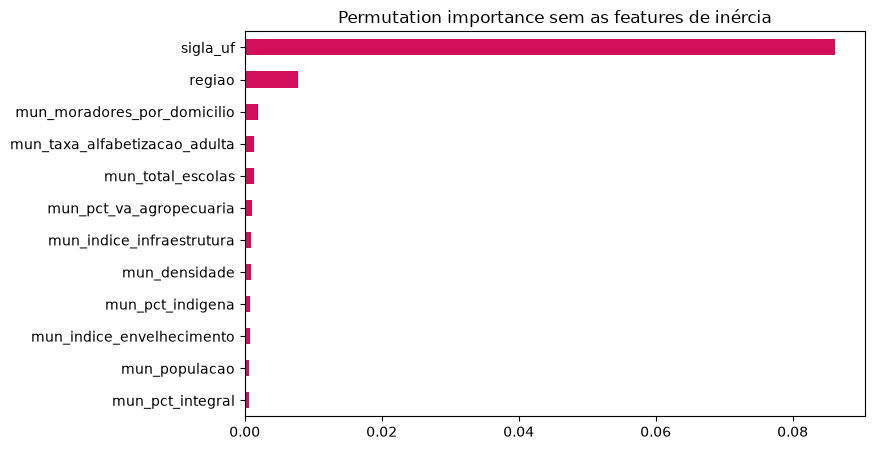

,queda do ROC-AUC
sigla_uf,0.0862
regiao,0.0078
mun_moradores_por_domicilio,0.0019
mun_taxa_alfabetizacao_adulta,0.0013
mun_total_escolas,0.0013
mun_pct_va_agropecuaria,0.0010
mun_indice_infraestrutura,0.0009
mun_densidade,0.0009
mun_pct_indigena,0.0008
mun_indice_envelhecimento,0.0007


In [12]:
INERCIA = ["mun_taxa_ano_anterior", "mun_distancia_meta_anterior"]
pipe_sem, res_sem, X_te_sem, y_te_sem, _ = treinar_e_avaliar(NOME, melhores_params, dados, excluir=INERCIA, teto=TETO_ALUNOS)
_, res_com, *_ = treinar_e_avaliar(NOME, melhores_params, dados, teto=TETO_ALUNOS)
display(pd.DataFrame({"com todas as features": res_com, "sem as features de inércia": res_sem}).T.round(4))

X_p, y_p, _ = limitar_por_municipio(X_te_sem, dados.y_teste, dados.g_teste, TETO_PERMUTACAO)
imp_sem = importancia_permutacao(pipe_sem, X_p, y_p, n_repeats=5)
fig, ax = plt.subplots(figsize=(8, 5))
imp_sem.head(12)[::-1].plot.barh(ax=ax, color="#D30F59")
ax.set_title("Permutation importance sem as features de inércia")
fig.savefig("../images/rf_importancia_sem_inercia.png", dpi=150, bbox_inches="tight")
plt.show()
display(imp_sem.head(10).round(4).to_frame("queda do ROC-AUC"))

**Como ler:** a queda de AUC mede quanto da capacidade preditiva vinha da inércia. As features
que sobem no ranking são candidatas a **fatores associados** ao risco, ainda como associação (não
causa).

**Resultado:** sem as duas features de inércia, o ROC-AUC cai de 0,672 para 0,647. O contexto
sozinho recupera 85% do ganho sobre o acaso: o resultado do ano anterior é, em grande parte, um
resumo do próprio contexto do município.

Os fatores do topo, na permutation:

1. **UF** (0,086) — de longe o mais forte. O estado em que o município está explica mais que
   qualquer variável socioeconômica.
2. **Região** (0,008).
3. **Moradores por domicílio** — domicílios mais adensados, sinal de vulnerabilidade.
4. **Alfabetização adulta** — escolaridade dos adultos do município.
5. **Total de escolas** — porte do município.

Fazem sentido para políticas públicas: condição das famílias e porte são fatores conhecidos na
literatura educacional, e o peso da UF aponta para diferenças de política estadual — ou de
medição, já que cada estado aplica a própria avaliação. A análise equivalente com o
HistGradientBoosting (`src/evaluation/interpretacao.py`, README seção 8) chega à mesma conclusão,
e detalha o efeito de cada estado.

## Síntese

In [13]:
linha = tabela_teste.iloc[1]
print(f"Modelo: Random Forest {melhores_params}")
print(f"Overfitting (AUC treino - validação): sem limites {tabela_overfit['gap AUC'].iloc[0]:.3f} | com limites {tabela_overfit['gap AUC'].iloc[1]:.3f}")
print(f"Busca: ROC-AUC entre {resultados_busca['roc_auc'].min():.3f} e {resultados_busca['roc_auc'].max():.3f}")
print(f"Teste (limiar {LIMIAR:.2f}): ROC-AUC {linha['roc_auc']:.3f} | PR-AUC {linha['pr_auc']:.3f} | recall {linha['recall']:.3f} | precisão {linha['precisao']:.3f}")
print("Top 5 SHAP:", ", ".join(shap_medio.head(5).index))
print("Top 5 permutation:", ", ".join(imp_perm.head(5).index))
print(f"RS: AUC {com_rs['roc_auc']:.3f} (treino com RS) vs {sem_rs_['roc_auc']:.3f} (sem RS)")
print(f"Sem inércia: AUC {res_com['roc_auc']:.3f} -> {res_sem['roc_auc']:.3f}; top 3: {', '.join(imp_sem.head(3).index)}")

Modelo: Random Forest {'n_estimators': 100, 'min_samples_leaf': 100, 'max_features': 'sqrt', 'max_depth': 12}
Overfitting (AUC treino - validação): sem limites 0.065 | com limites 0.048
Busca: ROC-AUC entre 0.683 e 0.685
Teste (limiar 0.35): ROC-AUC 0.673 | PR-AUC 0.548 | recall 0.773 | precisão 0.482
Top 5 SHAP: mun_taxa_ano_anterior, mun_distancia_meta_anterior, sigla_uf_MG, mun_total_escolas, sigla_uf_BA
Top 5 permutation: sigla_uf, mun_taxa_ano_anterior, mun_distancia_meta_anterior, regiao, mun_total_escolas
RS: AUC 0.673 (treino com RS) vs 0.673 (sem RS)
Sem inércia: AUC 0.672 -> 0.647; top 3: sigla_uf, regiao, mun_moradores_por_domicilio


**Próximos passos:** comparar com os demais modelos na tabela da seção 8 (`python -m
src.evaluation.comparar_teste`); decidir o recall-alvo com a capacidade de atendimento;
revisitar após corrigir `mun_pct_rural` e `mun_pct_transporte` na Gold.